In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [9]:
train = pd.read_csv("../data/splits/train.csv")
validation = pd.read_csv("../data/splits/validation.csv")
test = pd.read_csv("../data/splits/test.csv")

print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

Train: (4648, 5)
Validation: (1001, 5)
Test: (990, 5)


In [10]:
features = ["icare_iop", "cct"]
target = "applanation_iop"

X_train = train[features]
y_train = train[target]

X_validation = validation[features]
y_validation = validation[target]

X_test = test[features]
y_test = test[target]

In [11]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [12]:
model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [13]:
validation_predictions = model.predict(X_validation)

In [14]:
validation_mae = mean_absolute_error(
    y_validation,
    validation_predictions
)

validation_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        validation_predictions
    )
)

validation_r2 = r2_score(
    y_validation,
    validation_predictions
)

print("Validation Results")
print("------------------")
print(f"MAE:  {validation_mae:.3f} mmHg")
print(f"RMSE: {validation_rmse:.3f} mmHg")
print(f"R²:   {validation_r2:.3f}")

Validation Results
------------------
MAE:  3.401 mmHg
RMSE: 4.687 mmHg
R²:   0.555


In [15]:
# FINAL TEST EVALUATION

## Random Forest Hyperparameter Tuning
### Experiment 1: Number of Trees - 100

In [16]:
n_estimators_values = [10, 50, 100, 200, 500, 1000]

results = []

for n in n_estimators_values:

    model = RandomForestRegressor(
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_validation)

    mae = mean_absolute_error(y_validation, predictions)
    rmse = np.sqrt(mean_squared_error(y_validation, predictions))
    r2 = r2_score(y_validation, predictions)

    results.append({
        "n_estimators": n,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

results_df

,n_estimators,MAE,RMSE,R2
0,10,3.424901,4.720038,0.549203
1,50,3.406737,4.693180,0.554319
2,100,3.401312,4.687380,0.555420
3,200,3.402703,4.701531,0.552731
4,500,3.397330,4.690862,0.554759
5,1000,3.397895,4.691408,0.554655


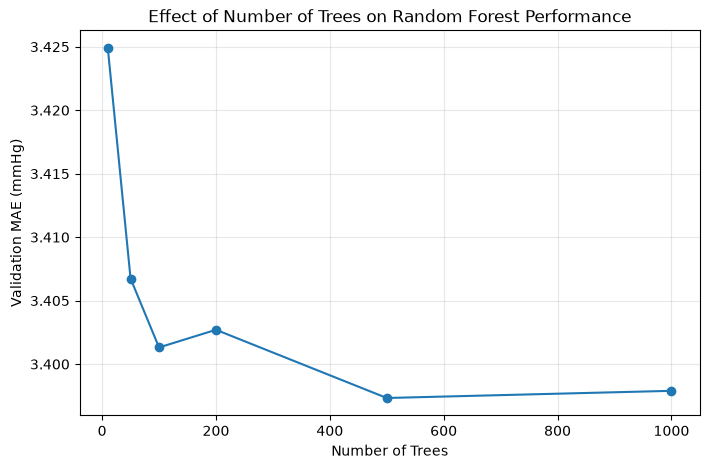

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["n_estimators"],
    results_df["MAE"],
    marker="o"
)

plt.xlabel("Number of Trees")
plt.ylabel("Validation MAE (mmHg)")
plt.title("Effect of Number of Trees on Random Forest Performance")

plt.grid(True, alpha=0.3)
plt.show()

## Random Forest Hyperparameter Tuning
### Experiment 2: Max Depth - 4

In [18]:
depth_values = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]

results = []

for depth in depth_values:

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_validation)

    mae = mean_absolute_error(y_validation, predictions)
    rmse = np.sqrt(mean_squared_error(y_validation, predictions))
    r2 = r2_score(y_validation, predictions)

    results.append({
        "max_depth": depth,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

results_df

,max_depth,MAE,RMSE,R2
0,2.0,3.047222,4.304606,0.625064
1,3.0,2.840608,4.049163,0.668243
2,4.0,2.806113,4.017061,0.673482
3,5.0,2.810410,4.044245,0.669048
4,6.0,2.837389,4.087243,0.661973
5,8.0,2.900710,4.171504,0.647892
6,10.0,2.998197,4.278224,0.629646
7,12.0,3.112824,4.394543,0.609233
8,15.0,3.282527,4.569627,0.577476
9,20.0,3.392947,4.677776,0.557239


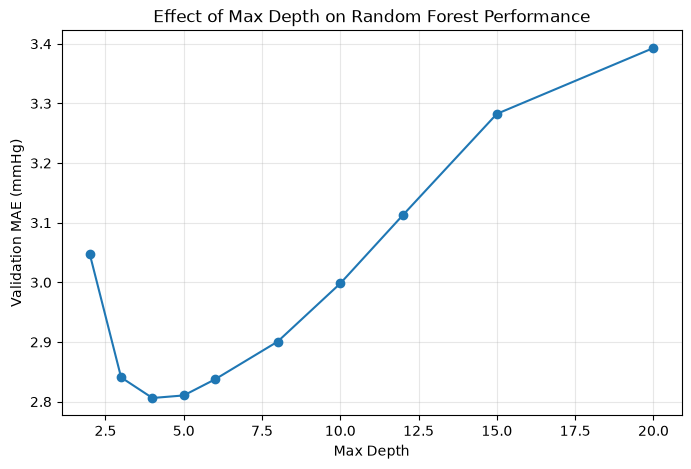

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["max_depth"],
    results_df["MAE"],
    marker="o"
)

plt.xlabel("Max Depth")
plt.ylabel("Validation MAE (mmHg)")
plt.title("Effect of Max Depth on Random Forest Performance")

plt.grid(True, alpha=0.3)
plt.show()

### Experiment 3: Minimum Samples per Leaf - 1

In [20]:
leaf_values = [1, 2, 3, 5, 10, 15, 20]

leaf_results = []

for leaf in leaf_values:

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=4,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_validation)

    mae = mean_absolute_error(y_validation, predictions)
    rmse = np.sqrt(mean_squared_error(y_validation, predictions))
    r2 = r2_score(y_validation, predictions)

    leaf_results.append({
        "min_samples_leaf": leaf,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

leaf_results_df = pd.DataFrame(leaf_results)

leaf_results_df

,min_samples_leaf,MAE,RMSE,R2
0,1,2.806113,4.017061,0.673482
1,2,2.806516,4.016920,0.673505
2,3,2.808391,4.017801,0.673362
3,5,2.809962,4.020711,0.672889
4,10,2.810713,4.019447,0.673094
5,15,2.806296,4.022807,0.672547
6,20,2.810671,4.034604,0.670624


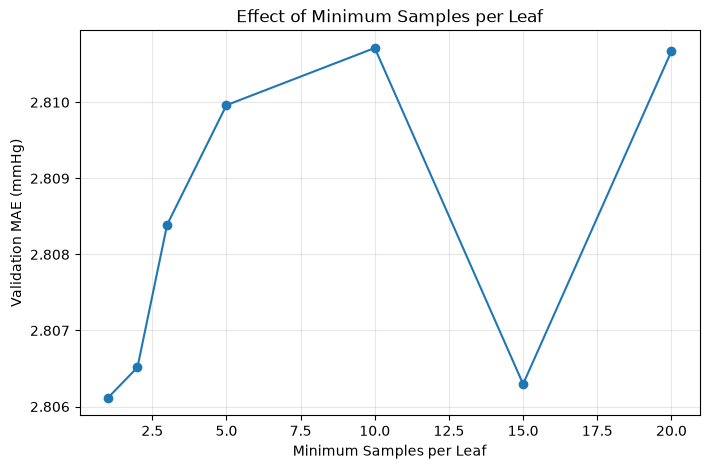

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(
    leaf_results_df["min_samples_leaf"],
    leaf_results_df["MAE"],
    marker="o"
)

plt.xlabel("Minimum Samples per Leaf")
plt.ylabel("Validation MAE (mmHg)")
plt.title("Effect of Minimum Samples per Leaf")

plt.grid(True, alpha=0.3)
plt.show()

### Experiment 4: Minimum Samples Required to Split

In [22]:
split_values = [2, 5, 10, 20, 30, 50]

split_results = []

for split in split_values:

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=4,
        min_samples_leaf=1,
        min_samples_split=split,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_validation)

    mae = mean_absolute_error(y_validation, predictions)
    rmse = np.sqrt(mean_squared_error(y_validation, predictions))
    r2 = r2_score(y_validation, predictions)

    split_results.append({
        "min_samples_split": split,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

split_results_df = pd.DataFrame(split_results)

split_results_df

,min_samples_split,MAE,RMSE,R2
0,2,2.806113,4.017061,0.673482
1,5,2.806113,4.017061,0.673482
2,10,2.806258,4.017189,0.673461
3,20,2.806409,4.018819,0.673196
4,30,2.807730,4.026240,0.671988
5,50,2.806324,4.021703,0.672727


In [23]:
### Experiment 5: Combined Hyperparameter Search

## Randomized Search

In [24]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "n_estimators": [50, 100, 200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "min_samples_split": [2, 5, 10, 20, 30],
    "min_samples_leaf": [1, 2, 3, 5, 10]
}

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=50,
    scoring="neg_mean_absolute_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


/home/abhay/projects/icare-ml/.venv/lib64/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/abhay/projects/icare-ml/.venv/lib64/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/abhay/projects/icare-ml/.venv/lib64/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/abhay/projects/icare-m

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [3, 4, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a functio

In [25]:
print("Best parameters:")
print(search.best_params_)

print("\nBest cross-validation MAE:")
print(-search.best_score_)

Best parameters:
{'n_estimators': 500, 'min_samples_split': 20, 'min_samples_leaf': 5, 'max_depth': 5}

Best cross-validation MAE:
2.8497705075052204


In [26]:
best_rf = search.best_estimator_

validation_predictions = best_rf.predict(X_validation)

mae = mean_absolute_error(y_validation, validation_predictions)
rmse = np.sqrt(mean_squared_error(y_validation, validation_predictions))
r2 = r2_score(y_validation, validation_predictions)

print("Validation Results")
print("------------------")
print(f"MAE:  {mae:.3f} mmHg")
print(f"RMSE: {rmse:.3f} mmHg")
print(f"R²:   {r2:.3f}")

Validation Results
------------------
MAE:  2.812 mmHg
RMSE: 4.039 mmHg
R²:   0.670


## Random Forest Residual Analysis

Now that we have tuned the Random Forest, we will examine its prediction errors in more detail.

A residual is the difference between the actual GAT IOP and the model's predicted GAT IOP:

Residual = Actual GAT IOP − Predicted GAT IOP

Residual analysis helps us determine whether the model's errors are random or whether there are systematic patterns in its predictions.

In [27]:
best_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=4,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

best_model.fit(X_train, y_train)

validation_predictions = best_model.predict(X_validation)

In [28]:
residuals = y_validation - validation_predictions

print("Mean residual:", residuals.mean())
print("Minimum residual:", residuals.min())
print("Maximum residual:", residuals.max())

Mean residual: 0.15254738263535686
Minimum residual: -19.810327573234602
Maximum residual: 22.952567434586104


### Residuals vs Predicted IOP

The following plot shows whether prediction errors change systematically with the predicted IOP.

Ideally, residuals should be randomly distributed around zero.

A visible pattern may indicate that the model is systematically overpredicting or underpredicting certain IOP ranges.

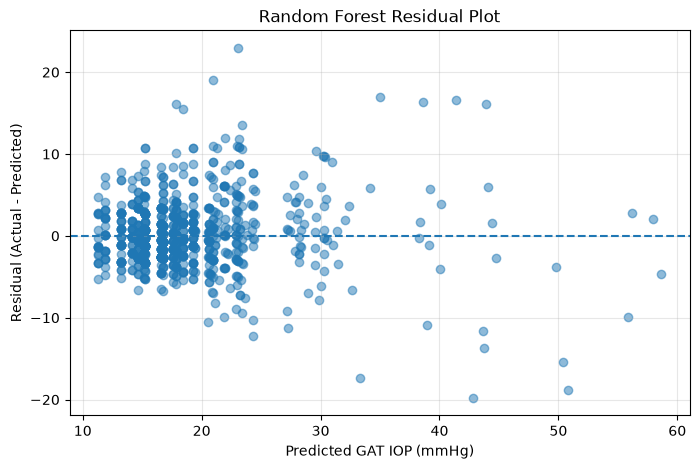

In [29]:
plt.figure(figsize=(8, 5))

plt.scatter(
    validation_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted GAT IOP (mmHg)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Random Forest Residual Plot")

plt.grid(True, alpha=0.3)
plt.show()

## Actual vs Predicted GAT IOP

We now compare the model's predicted GAT IOP directly with the actual GAT IOP.

A perfect model would place every prediction on the 45° line:

Predicted GAT = Actual GAT

The distance of each point from this line represents prediction error.

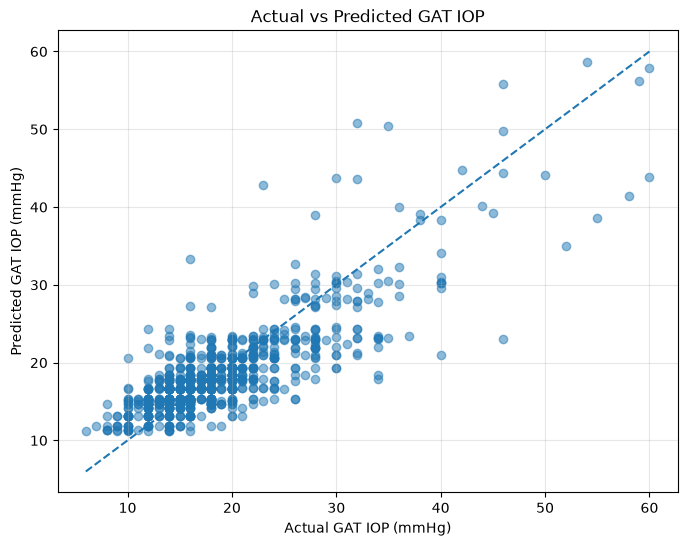

In [30]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_validation,
    validation_predictions,
    alpha=0.5
)

# Perfect prediction line
min_iop = min(y_validation.min(), validation_predictions.min())
max_iop = max(y_validation.max(), validation_predictions.max())

plt.plot(
    [min_iop, max_iop],
    [min_iop, max_iop],
    linestyle="--"
)

plt.xlabel("Actual GAT IOP (mmHg)")
plt.ylabel("Predicted GAT IOP (mmHg)")
plt.title("Actual vs Predicted GAT IOP")

plt.grid(True, alpha=0.3)
plt.show()

## Error by IOP Range

The overall MAE can hide differences in model performance across the IOP range.

We divide the validation samples into clinically meaningful IOP ranges and calculate MAE and RMSE for each range.

In [31]:
iop_ranges = [
    ("<10", y_validation < 10),
    ("10-20", (y_validation >= 10) & (y_validation < 20)),
    ("20-30", (y_validation >= 20) & (y_validation < 30)),
    ("30-40", (y_validation >= 30) & (y_validation < 40)),
    ("40+", y_validation >= 40)
]

range_results = []

for name, mask in iop_ranges:
    actual = y_validation[mask]
    predicted = validation_predictions[mask]

    range_results.append({
        "IOP Range": name,
        "Samples": len(actual),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    })

range_results_df = pd.DataFrame(range_results)

range_results_df

,IOP Range,Samples,MAE,RMSE
0,<10,15,3.807711,3.992266
1,10-20,641,2.091863,2.802042
2,20-30,267,3.097431,4.022745
3,30-40,55,6.849033,8.345349
4,40+,23,9.009060,10.894521


## Target Distribution

We examine the distribution of GAT IOP in the training set.

This helps determine whether the model has enough training examples across the full IOP range, particularly at high IOP values where the residual analysis showed substantially larger errors.

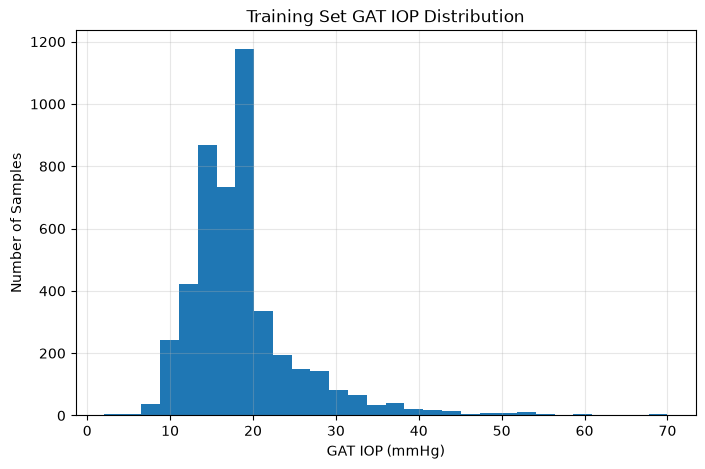

In [32]:
plt.figure(figsize=(8, 5))

plt.hist(
    y_train,
    bins=30
)

plt.xlabel("GAT IOP (mmHg)")
plt.ylabel("Number of Samples")
plt.title("Training Set GAT IOP Distribution")

plt.grid(True, alpha=0.3)
plt.show()

In [33]:
bins = [0, 10, 20, 30, 40, 50, 60, 80]

train_distribution = pd.cut(
    y_train,
    bins=bins,
    right=False
).value_counts().sort_index()

train_distribution

applanation_iop
[0, 10)       64
[10, 20)    2947
[20, 30)    1300
[30, 40)     229
[40, 50)      65
[50, 60)      30
[60, 80)      13
Name: count, dtype: int64

## Random Forest Overfitting Check

We compare the model's performance on the training and validation datasets.

A large difference between training and validation performance would indicate overfitting.

A small difference suggests that the model is generalizing reasonably well and that further increasing model complexity is unlikely to provide substantial benefit.

In [34]:
best_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=4,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

best_model.fit(X_train, y_train)

train_predictions = best_model.predict(X_train)
validation_predictions = best_model.predict(X_validation)

In [36]:
train_mae = mean_absolute_error(y_train, train_predictions)
train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
train_r2 = r2_score(y_train, train_predictions)

val_mae = mean_absolute_error(y_validation, validation_predictions)
val_rmse = np.sqrt(mean_squared_error(y_validation, validation_predictions))
val_r2 = r2_score(y_validation, validation_predictions)

print("Training")
print("------------------")
print(f"MAE:  {train_mae:.3f}")
print(f"RMSE: {train_rmse:.3f}")
print(f"R²:   {train_r2:.3f}")

print("\nValidation")
print("------------------")
print(f"MAE:  {val_mae:.3f}")
print(f"RMSE: {val_rmse:.3f}")
print(f"R²:   {val_r2:.3f}")

Training
------------------
MAE:  2.797
RMSE: 3.778
R²:   0.724

Validation
------------------
MAE:  2.806
RMSE: 4.017
R²:   0.673


## Final Random Forest Test Evaluation

The Random Forest has now been tuned using the training and validation datasets.

The test dataset has remained untouched during model development and hyperparameter tuning.

We now evaluate the finalized Random Forest on the test dataset to obtain an unbiased estimate of its performance on previously unseen patients.

The primary evaluation metrics are:

- **MAE:** average absolute prediction error in mmHg.
- **RMSE:** penalizes larger prediction errors more strongly.
- **R²:** proportion of variation in GAT IOP explained by the model.

In [37]:
test_predictions = best_model.predict(X_test)

test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)

print("Final Random Forest Test Results")
print("------------------")
print(f"MAE:  {test_mae:.3f} mmHg")
print(f"RMSE: {test_rmse:.3f} mmHg")
print(f"R²:   {test_r2:.3f}")

Final Random Forest Test Results
------------------
MAE:  2.920 mmHg
RMSE: 4.000 mmHg
R²:   0.728
